In [2]:
import os
import numpy as np
import random
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

from glob import glob
from tqdm import tqdm
from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from torchvision import tv_tensors
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision.transforms import v2
from torchvision.transforms.v2 import functional as TVF
from torchvision import models
import torch.nn.functional as F

import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor, StochasticWeightAveraging
from lightning.pytorch.loggers import CSVLogger

from skimage import io
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE

# 3 OpenSet classification model

## Model architecture definition

For a resolving of the Open-Set classification task in the scope of our research we utilized an Class Anchor Clustering approach [1], where as an encoder has been utilized a novel pretrained transformer-based neural network DINOv2[2] with embedding vector size of 384 (the smallest version) and a Fully-Connected layer as classsification layer.

***References:*** 

[1] D. Miller, N. Suenderhauf, M. Milford, and F. Dayoub, ‘Class Anchor Clustering: A Loss for Distance-Based Open Set Recognition’, in Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision, pp. 3570–3578.

[2] M. Oquab et al., ‘DINOv2: Learning Robust Visual Features without Supervision’, arXiv:2304. 07193. 2023.


```
@misc{oquab2023dinov2,
  title={DINOv2: Learning Robust Visual Features without Supervision},
  author={Oquab, Maxime and Darcet, Timothée and Moutakanni, Theo and Vo, Huy and Szafraniec, Marc and Khalidov, Vasil and Fernandez, Pierre and Haziza, Daniel and Massa, Francisco and El-Nouby, Alaaeldin and Howes, Russell and Huang, Po-Yao and Xu, Hu and Sharma, Vasu and Li, Shang-Wen and Galuba, Wojciech and Rabbat, Mike and Assran, Mido and Ballas, Nicolas and Synnaeve, Gabriel and Misra, Ishan and Jegou, Herve and Mairal, Julien and Labatut, Patrick and Joulin, Armand and Bojanowski, Piotr},
  journal={arXiv:2304.07193},
  year={2023}
}

@inproceedings{millerclass,
  title={Class Anchor Clustering: A Loss for Distance-Based Open Set Recognition},
  author={Miller, Dimity and Suenderhauf, Niko and Milford, Michael and Dayoub, Feras},
  booktitle={Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision},
  pages={3570--3578}
}
```

In [3]:
from common.configuration import DatasetPath, ModelPath, species_invasive

## Dataset

In [4]:
OBJECTS_ROOT = DatasetPath.reference_images

In [5]:
from common.img_utils import pad2size, scale2factor

class PollenClassificationDataset(Dataset):
    def __init__(self, dataset, classes_map, 
                 static_transform=None, 
                 random_transform=None):
        self.known_classes_numbers = list(classes_map.values())
        self.classes_map = classes_map
        self.transform = random_transform
        self._all_samples = []
        self._class_to_indices = {i: [] for i,c in enumerate(self.known_classes_numbers)}
        
        total_samples = 0
        for idx, sample in enumerate(tqdm(dataset)):
            img = Image.open(sample["image"])
            if sample["label"] in classes_map:
                c_number = classes_map[sample["label"]]
            else:
                c_number = 0
            if static_transform is not None:
                img = static_transform(img)
            self._all_samples.append((c_number, img))
            self._class_to_indices[c_number].append(total_samples)
            total_samples += 1
        print(f"Total samples: {total_samples}")

    def __len__(self):
        return len(self._all_samples)

    def __getitem__(self, idx):
        if idx >= len(self._all_samples):
            raise IndexError("Index out of range")
        label, anchor = self._all_samples[idx]
        
        if self.transform:
            anchor = self.transform(anchor)
        
        anchor = torch.as_tensor(anchor) if not isinstance(anchor, torch.Tensor) else anchor

        label = torch.as_tensor(label) if not isinstance(label, torch.Tensor) else label

        return anchor, label.long()

In [6]:
def load_dataset(data_dir: str, required_unknown: list) -> tuple:
    """ Returns PollenClassificationDataset tuple: (dataset_train, dataset_val, dataset_test) """
    all_classes = [item for item in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, item))]
    # all_classes.remove("Unknown") 

    print(f"All known classes: {all_classes}")
    train_classes = all_classes
    pseudo_unknown_classes = []
    for c in required_unknown:
        train_classes.remove(c)
        pseudo_unknown_classes.append(c)

    classes_map = {value:key for key, value in enumerate(train_classes)}
    classes_map["Unknown"] = -1

    # train_classes, val_classes = train_test_split(train_classes, test_size=0.2, random_state=42)
    trainval_dataset = []
    test_dataset = []
    for c in tqdm(train_classes):
        if not os.path.isdir(os.path.join(data_dir, c)):
            continue
        images = glob(os.path.join(data_dir, c, "*.png"))
        names = [os.path.split(n)[1].rsplit("_", maxsplit=1)[0] for n in images]
        names.sort()
        names = list(set(names))
        trainval_pictures, test_pictures = train_test_split(names, test_size=0.2, random_state=42)
        for pic in trainval_pictures:
            trainval_img =  glob(os.path.join(data_dir, c, f"{pic}*.png"))
            trainval_dataset.extend([{"label": c, "image": im} for im in trainval_img])
        for pic in test_pictures:
            test_img =  glob(os.path.join(data_dir, c, f"{pic}*.png"))
            test_dataset.extend([{"label": c, "image": im} for im in test_img])
    for c in tqdm(pseudo_unknown_classes):
        if not os.path.isdir(os.path.join(data_dir, c)):
            continue
        images = glob(os.path.join(data_dir, c, "*.png"))
        names = [os.path.split(n)[1].rsplit("_", maxsplit=1)[0] for n in images]
        names.sort()
        names = list(set(names))
        for pic in names:
            test_img =  glob(os.path.join(data_dir, c, f"{pic}*.png"))
            test_dataset.extend([{"label": c, "image": im} for im in test_img])
    
    print(f"Known train classes: {train_classes}")
    print(f"Pseudo unknown classes (for test): {pseudo_unknown_classes}")

    train_dataset, val_dataset = train_test_split(trainval_dataset, test_size=0.2, random_state=42)
    print(f"Train dataset size: {len(train_dataset)}")
    print(f"Validation dataset size: {len(val_dataset)}")
    print(f"Test dataset size: {len(test_dataset)}")
    
    static_transforms = v2.Compose([
        v2.Lambda(scale2factor),
        v2.Lambda(pad2size),
        # v2.PILToTensor(),
        # v2.ToDtype(torch.float32, scale=True),
        # v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    train_dinamic_transforms = v2.Compose([
        # v2.Lambda(scale2factor),
        # v2.Lambda(pad2size),
        # v2.AutoAugment(v2.AutoAugmentPolicy.IMAGENET),
        v2.RandomHorizontalFlip(p=0.5),
        v2.RandomEqualize(),
        v2.RandomVerticalFlip(p=0.5),
        v2.RandomRotation(180),
        v2.RandomAutocontrast(),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    val_dinamic_transforms = v2.Compose([
        # v2.Lambda(scale2factor),
        # v2.Lambda(pad2size),
        # v2.AutoAugment(v2.AutoAugmentPolicy.IMAGENET),
        v2.PILToTensor(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    print("\nLoad Train Dataset")
    dataset_train = PollenClassificationDataset(train_dataset, classes_map, static_transform=static_transforms, random_transform = train_dinamic_transforms)
    print("\nLoad Validation Dataset")
    dataset_val = PollenClassificationDataset(val_dataset, classes_map, static_transform=static_transforms, random_transform = val_dinamic_transforms)
    print("\nLoad Test Dataset")
    dataset_test = PollenClassificationDataset(test_dataset, classes_map, static_transform=static_transforms, random_transform = val_dinamic_transforms)
    return classes_map, dataset_train, dataset_val, dataset_test

classes_map, dataset_train, dataset_val, dataset_test = load_dataset(OBJECTS_ROOT, species_invasive)

label_map = {v: k for k, v in classes_map.items()}

All known classes: ['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Fraxinus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Urtica', 'Ambrosia', 'Ulmus', 'Malus', 'Taraxacum']


100%|██████████| 2/2 [00:00<00:00, 16.46it/s]


Known train classes: ['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula', 'Chenopodiaceae', 'Corylus', 'Fraxinus', 'Picea', 'Pinus', 'Plantago', 'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia', 'Urtica', 'Ambrosia', 'Ulmus']
Pseudo unknown classes (for test): ['Taraxacum', 'Malus']
Train dataset size: 1907
Validation dataset size: 477
Test dataset size: 1034

Load Train Dataset


100%|██████████| 1907/1907 [00:04<00:00, 435.58it/s]


Total samples: 1907

Load Validation Dataset


100%|██████████| 477/477 [00:01<00:00, 397.65it/s]


Total samples: 477

Load Test Dataset


100%|██████████| 1034/1034 [00:02<00:00, 416.84it/s]

Total samples: 1034


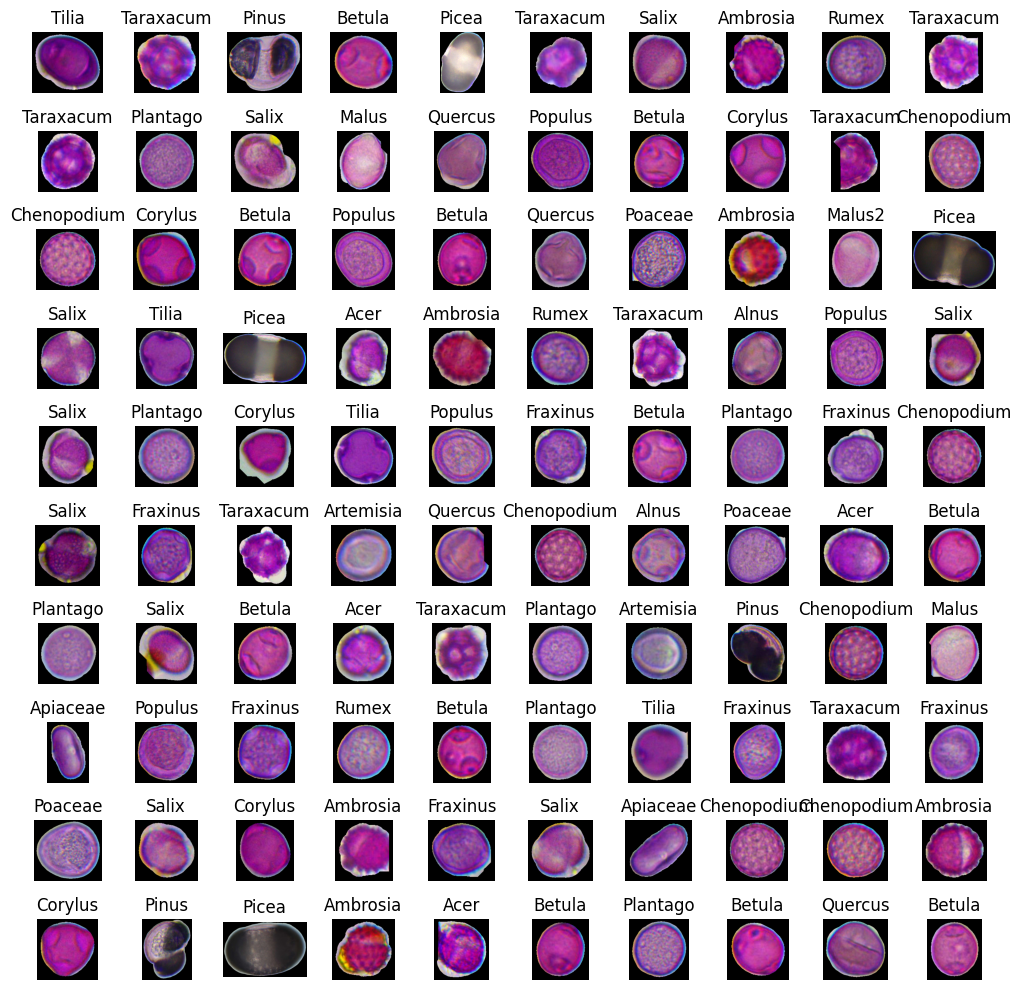

In [7]:
all_obj_images = glob(os.path.join(OBJECTS_ROOT,  "**", "*.png"), recursive=True)
all_obj_images = random.sample(all_obj_images, 100)
fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(10, 10))
for ax, img_path in zip(axs.flatten(), all_obj_images):
    image_rgb = io.imread(img_path)
    ax.set_title(os.path.basename(img_path).split(" ")[0].split("_")[0])
    ax.imshow(image_rgb)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Utils

In [8]:
def plot(imgs, row_title=None, labels=None, **imshow_kwargs):
    if labels != None:
        ax_title = True
    else:
        ax_title = False
    if not isinstance(imgs[0], list):
        # Make a 2d grid even if there's just 1 row
        imgs = [imgs]

    num_rows = len(imgs)
    num_cols = len(imgs[0])
    _, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
    for row_idx, row in enumerate(imgs):
        for col_idx, img in enumerate(row):
            boxes = None
            masks = None
            if isinstance(img, tuple):
                img, target = img
                if isinstance(target, dict):
                    boxes = target.get("boxes")
                    masks = target.get("masks")
                elif isinstance(target, tv_tensors.BoundingBoxes):
                    boxes = target
                else:
                    raise ValueError(f"Unexpected target type: {type(target)}")
            img = TVF.to_image(img)
            if img.dtype.is_floating_point and img.min() < 0:
                # Poor man's re-normalization for the colors to be OK-ish. This
                # is useful for images coming out of Normalize()
                img -= img.min()
                img /= img.max()

            img = TVF.to_dtype(img, torch.uint8, scale=True)
            black_pixels = (img != 0).all(dim=0)
            img[:, ~black_pixels] = 255
            if boxes is not None:
                img = draw_bounding_boxes(img, boxes, colors="yellow", width=3)
            if masks is not None:
                img = draw_segmentation_masks(img, masks.to(torch.bool), colors=["green"] * masks.shape[0], alpha=.65)

            ax = axs[row_idx, col_idx]
            ax.imshow(img.permute(1, 2, 0).numpy(), **imshow_kwargs)
            ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])
            if ax_title:
                ax.set_title(labels[col_idx])

    if row_title is not None:
        for row_idx in range(num_rows):
            axs[row_idx, 0].set(ylabel=row_title[row_idx])

    plt.tight_layout()

## Neural Network Training 

In [8]:
train_loader = torch.utils.data.DataLoader(
    dataset_train,
    batch_size= 96,
    shuffle= True,
    num_workers= 6
)
val_loader = torch.utils.data.DataLoader(
    dataset_val,
    batch_size= 4,
    shuffle= False,
    num_workers= 6
)
test_loader = torch.utils.data.DataLoader(
    dataset_test,
    batch_size= 6,
    shuffle= False,
    num_workers= 6
)

In [ ]:
for anchor, label in train_loader:
    plot(anchor[:6], row_title=["anchor"], labels=[label_map[l.item()] for l in label[:6]])
    break

Import the model definition from the common module.

In [9]:
from common.osc_classification import OpenSetClassificationModel

Next, define CACLoss

In [10]:
class CACLoss(nn.Module):
    def __init__(self, num_known_classes, lbda=0.1):
        super().__init__()
        self.num_known_classes = num_known_classes
        self.lbda = lbda

    def forward(self, distances, gt):
        '''Returns CAC loss, as well as the Anchor and Tuplet loss components separately for visualisation.'''
        true = torch.gather(distances, 1, gt.view(-1, 1)).view(-1)
        non_gt = torch.Tensor([[i for i in range(self.num_known_classes) if gt[x] != i] for x in range(len(distances))]).long().cuda()
        others = torch.gather(distances, 1, non_gt)
    	
        anchor = torch.mean(true)
    
        tuplet = torch.exp(-others+true.unsqueeze(1))
        tuplet = torch.mean(torch.log(1+torch.sum(tuplet, dim = 1)))
    
        total = self.lbda*anchor + tuplet
    
        return total, anchor, tuplet

To simplification of the tarining process, we used a pytorch lightning, thus, define a wrapper for the model.

In [11]:
class PollenOSCEmbeddingsModule(L.LightningModule):
    def __init__(self,
                 n_classes,
                 alpha=10, # Magnitude of the anchor point
                 optim_lr=0.001,
                 optim_betas=(0.9, 0.999),
                 optim_eps=1e-08,
                 optim_weight_decay=0.01,
                 check_val=20,
                 freeze_epochs=10):
        super().__init__()
        # call this to save (arguments) to the checkpoint
        self.save_hyperparameters()
        self.lr = optim_lr

        self.cac_loss = CACLoss(n_classes)
        
        self.best_score = 1
        self.best_val_epoch = -1

        self.model = OpenSetClassificationModel(n_classes=n_classes)
        
        # initialising with anchors
        anchors = torch.diag(torch.Tensor([alpha for i in range(n_classes)]))	
        self.model.set_anchors(anchors)

        self.train_step_outputs = []
        self.val_step_outputs = []
        self.test_step_outputs = []
        self.train_losses = []
        self.val_losses = []
        self.test_losses = []

        self.freeze_backbone()

    def freeze_backbone(self):
        for param in self.model.model.parameters():
            param.requires_grad = False

    def unfreeze_all(self):
        for param in self.model.parameters():
            param.requires_grad = True

    def on_train_epoch_start(self):
        pass
        # if self.current_epoch == self.hparams.freeze_epochs:
        #     self.unfreeze_all()

    def forward(self, inputs):
        return self.model(inputs)

    def _shared_eval_step(self, batch, batch_idx):
        anchor, label = batch
        l_anchor = len(anchor)
        outputs = self.model(anchor)
        loss, anchorLoss, tupletLoss = self.cac_loss(outputs[1], label)
        return loss, l_anchor

    def training_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"train_loss": loss, "train_number": l_anchor_out}
        self.train_step_outputs.append(pred)
        return loss

    def on_train_epoch_end(self):
        outputs = self.train_step_outputs
        train_loss, num_items = 0, 0
        for output in outputs:
            train_loss += output["train_loss"].sum().item()
            num_items += output["train_number"]

        mean_train_loss = torch.tensor(train_loss / num_items)
        self.log("train_loss", mean_train_loss)
        self.train_losses.append(mean_train_loss.item())
        self.train_step_outputs.clear()  # free memory

    def validation_step(self, batch, batch_idx):
        loss, l_anchor_out = self._shared_eval_step(batch, batch_idx)
        pred = {"val_loss": loss, "val_number": l_anchor_out}
        self.val_step_outputs.append(pred)

    def on_validation_epoch_end(self):
        outputs = self.val_step_outputs
        val_loss, num_items = 0, 0
        for output in outputs:
            val_loss += output["val_loss"].sum().item()
            num_items += output["val_number"]

        mean_val_loss = torch.tensor(val_loss / num_items)
        self.val_losses.append(mean_val_loss.item())
        self.val_step_outputs.clear()  # free memory
        
        tensorboard_logs = {
            "val_loss": mean_val_loss
        }
        self.log("val_loss", mean_val_loss)

        if mean_val_loss < self.best_score:
            self.best_score = mean_val_loss
            self.best_val_epoch = self.current_epoch

    def test_step(self, batch, batch_idx):
        anchor, label = batch
        anchor_emb, anchor_out = self.model(anchor)
        celoss = self.celoss(anchor_out, label)
        loss = celoss
        l_anchor_out = len(anchor_out)

        true_pred = 0
        for i,l in enumerate(label):
            if torch.argmax(l).item() == torch.argmax(anchor_out).item():
                true_pred += 1
        acc = true_pred / l_anchor_out
        pred = {"test_loss": loss, "test_number": l_anchor_out, "test_acc": acc}
        self.test_step_outputs.append(pred)

    def on_test_epoch_end(self):
        outputs = self.test_step_outputs
        test_loss, num_items, test_acc = 0, 0, 0
        for output in outputs:
            test_loss += output["test_loss"].sum().item()
            num_items += output["test_number"]
            test_acc += output["test_acc"]
        mean_test_loss = torch.tensor(test_loss / num_items)
        mean_test_acc = torch.tensor(test_acc / len(outputs))
        print('mean_test_loss', mean_test_loss)
        print('mean_test_acc', mean_test_acc)
        self.test_losses.append(mean_test_loss.item())
        self.log('mean_test_loss', mean_test_loss)
        self.log('mean_test_acc', mean_test_acc)
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        
        self.optimizer = torch.optim.Adagrad(
            [
                {'params': self.model.model.parameters(), 'lr': 0.0},
                {'params': self.model.classifier.parameters(), 'lr': self.lr},
            ],
            lr=self.lr,
            eps=self.hparams.optim_eps,
            weight_decay=self.hparams.optim_weight_decay
        )
        return {
            "optimizer": self.optimizer,
            "lr_scheduler": {
                "scheduler": ReduceLROnPlateau(self.optimizer, factor=0.3, patience=5),
                "frequency": self.hparams.check_val,
                "monitor": "val_loss",
                "interval": "epoch",
            }
        }

    def plot_losses(self):
        plt.figure(figsize=(10, 5))
        plt.plot([i for i in range(len(self.train_losses))], self.train_losses, label='Train Loss')
        plt.plot([i * self.hparams.check_val for i in range(len(self.val_losses))], self.val_losses, label='Validation Loss')
        plt.xlabel('Iterations')
        plt.ylabel('Loss')
        plt.title('Training and Validation Losses')
        plt.legend()
        plt.show()

Create and prepare for training an instance of the Model.

In [ ]:
model = PollenOSCEmbeddingsModule(n_classes=len(label_map), check_val=3, freeze_epochs=30) # Do not train backbone
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Use device: {device}")
model = model.to(device)

Define callbacks for the training process

In [ ]:
checkpoint_callback = ModelCheckpoint(
    filename='checkpoint-Adagrad-{epoch:02d}-{val_loss:.2f}',
    # auto_insert_metric_name=False,
    dirpath="./history",
    monitor='val_loss',
    mode='min')
lr_logger = LearningRateMonitor()
logger = CSVLogger("logs", name="triplet_cos_2")

swa = StochasticWeightAveraging(swa_lrs=0.01)

### Learning rate optimization

To optimize learning rate we utilized an appoach implemented in Pytorch Lightning library which is based on idea proposed by L. Smith [1]

[1] L. N. Smith, ‘Cyclical Learning Rates for Training Neural Networks’, in 2017 IEEE Winter Conference on Applications of Computer Vision (WACV), 2017, pp. 464–472.

In [ ]:
trainer = L.Trainer(logger=logger,
                    log_every_n_steps=2,  # Increase, if epoch size is large
                    callbacks=[checkpoint_callback, lr_logger, swa],
                    precision="16-mixed",
                    check_val_every_n_epoch=model.hparams.check_val,
                    max_epochs=100,
                    # accumulate_grad_batches=2,
                    )

In [ ]:
tuner = L.pytorch.tuner.Tuner(trainer)
lf_finder = tuner.lr_find(model,
            train_dataloaders=train_loader)

fig = lf_finder.plot(suggest=True)
fig.show()

Print the suggested learning rate.

In [ ]:
lf_finder.suggestion()

And hyperparameters of the network.

In [ ]:
model.hparams

Next, apply LR suggestion to the model.

In [ ]:
model.lr = lf_finder.suggestion()
model.hparams.optim_lr = lf_finder.suggestion()

### Training loop and results

Start a training process of the model.

In [ ]:
trainer.fit(model, 
            train_dataloaders=train_loader, 
            val_dataloaders=val_loader,     
)

Plot curves of loss changes during training

In [ ]:
model.plot_losses()

## OSC NN Model Validation

In [ ]:
def prepare_data(embeddings_lists: list, labels_lists: list):
    all_labels_sorted = []
    all_embeddings_sorted = []
    class_boundaries = [0]
    for i, embeddings_list in enumerate(embeddings_lists):
        labels_list = labels_lists[i]
        class_to_idx = {}
        for i, class_name in enumerate(np.unique(labels_list)):
            class_to_idx[class_name] = i
        all_labels_idx = [class_to_idx[label] for label in labels_list]
        sorted_indices = sorted(range(len(embeddings_list)), key=lambda i: all_labels_idx[i])
        start = len(all_labels_sorted) + 1
        all_embeddings_sorted.extend([embeddings_list[i] for i in sorted_indices])
        all_labels_sorted.extend([labels_list[i] for i in sorted_indices])
    
        for i in range(start, len(all_labels_sorted)):
            if all_labels_sorted[i] != all_labels_sorted[i-1]:
                class_boundaries.append(i)
        class_boundaries.append(len(all_labels_sorted))

    return all_labels_sorted, all_embeddings_sorted, class_boundaries

In [ ]:
def add_class_markings(ax, class_boundaries, labels):
    tick_locs = [(class_boundaries[i] + class_boundaries[i+1] - 1) / 2 for i in range(len(class_boundaries)-1)]
    ax.set_xticks(tick_locs)
    ax.set_yticks(tick_locs)
    ax.set_xticklabels([labels[int(loc)] for loc in tick_locs])
    ax.set_yticklabels([labels[int(loc)] for loc in tick_locs])
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for boundary in class_boundaries[1:-1]:
        ax.axhline(y=boundary-1, color='k', linestyle='-', linewidth=1)
        ax.axvline(x=boundary-1, color='k', linestyle='-', linewidth=1)

In [ ]:
def plot_matrix(embeddings_lists: list, labels_lists: list, subtitle: str=None, axes_class_markings: bool=True):
    all_labels_sorted, all_embeddings_sorted, class_boundaries = prepare_data(embeddings_lists, labels_lists)

    pairwise_dist = pairwise_distances(all_embeddings_sorted, metric="euclidean")#cosine
    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(pairwise_dist, cmap='Blues_r')#, norm=PowerNorm(gamma=0.5, vmin=0, vmax=1)
    plt.colorbar(im, fraction=0.046, pad=0.04)

    if axes_class_markings:
        add_class_markings(ax, class_boundaries, all_labels_sorted)

    if subtitle != None:
        plt.title('Pairwise Distance Matrix\n' + subtitle)
    else:
        plt.title('Pairwise Distance Matrix')
    plt.tight_layout()
    plt.show()
    del all_labels_sorted
    del all_embeddings_sorted
    del class_boundaries

In [ ]:
from common.osc_classification import distance_to_scores, scores_to_class

In [ ]:
def process_loader(model, loader):
    all_embeddings = []
    all_predictions = []
    all_labels = []
    with torch.no_grad():
        for batch in loader:
            imgs, labels = batch
            labels_str = [label_map[l.item()] for l in labels]
            
            imgs = imgs.cuda()
            embeddings, pred_distances = model(imgs)
            scores = distance_to_scores(pred_distances)
            prediction = scores_to_class(scores, 4.0)
            predict_str = [label_map[l.item()] for l in prediction.cpu()]
            
            all_embeddings.append(embeddings.cpu())
            all_labels.extend(labels_str)
            all_predictions.extend(predict_str)
        all_embeddings = torch.cat(all_embeddings, dim=0).cpu().numpy()
        
    return all_embeddings, all_labels, all_predictions

In [ ]:
loaders_list = [test_loader, val_loader, train_loader] #test_loader, val_loader, train_loader
embeddings_data = []
labels_data_str = []
labels_predictions = []

### Distance matrices and accuracy estimation

In [ ]:
from common.stats import plot_confusion_matrix

titles = ["Test", "Validation", "Train"]
i = 0
for loader in tqdm(loaders_list):
    print("-" * 10, titles[i], "-" * 10)
    i += 1
    embeddings, labels, preds = process_loader(model.cuda(), loader)
    embeddings_data.append(embeddings)
    labels_data_str.append(labels)
    labels_predictions.append(preds)
    plot_matrix([embeddings], [labels], 'CAC Loss')
    plot_confusion_matrix(labels, preds)
    print(classification_report(labels, preds))

### Feature space analysis

To analyze feature space we projected it into 2-dimentional space using T-SNE method.

In [ ]:
def plot_tsne(embeddings_data, labels_data_str, subtitle: str = None):
    class_to_indices = {c: [] for c in np.unique(labels_data_str)}
    for i, label in enumerate(labels_data_str):
        class_to_indices[label].append(i)
    vectors = np.array(embeddings_data)
    colors = matplotlib.colormaps['tab20'].colors
    
    labels = [""] * vectors.shape[0]
    print(len(labels))
    for class_name, indices in class_to_indices.items():
        for index in indices:
            labels[index] = class_name
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=20, metric="euclidean", n_iter=2000, n_jobs=-1, early_exaggeration=12)#cosine
    vectors_2d = tsne.fit_transform(vectors)
    
    plt.figure(figsize=(8, 6))
    for i, (class_name, indices) in enumerate(class_to_indices.items()):
        mask = np.isin(range(vectors.shape[0]), indices)
        plt.scatter(vectors_2d[mask, 0], vectors_2d[mask, 1], 
                    label=class_name, color=colors[i], alpha=0.6)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    if subtitle: 
        plt.title("t-SNE visualization of image features\n"+subtitle)
    else:
        plt.title("t-SNE visualization of image features")
    plt.tight_layout()
    plt.show()

In [ ]:
import itertools
titles = ["test", "validation", "train", "All"]
for i, dataset in enumerate(embeddings_data + [np.vstack(embeddings_data), ]):
    plot_tsne(dataset, 
              (labels_data_str + [list(itertools.chain.from_iterable(labels_data_str)),])[i], 
              titles[i])

In [ ]:
os.makedirs(os.path.dirname(ModelPath.osc_classification), exist_ok=True)
os.rename(checkpoint_callback.best_model_path, ModelPath.osc_classification)

## Save pure OSC model as Pytorch

In [16]:
# model = PollenOSCEmbeddingsModule.load_from_checkpoint(checkpoint_callback.best_model_path)
model = PollenOSCEmbeddingsModule.load_from_checkpoint(r"C:\Users\siniz\Downloads\checkpoint-Adagrad-epoch=98-val_loss=0.23.ckpt")
torch.save(model.model.state_dict(), ModelPath.osc_classification)


Using cache found in C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main
